In [ ]:
# Path setup: notebooks live in notebooks/, but every path below is relative to the repo root
import os
from pathlib import Path

_here = Path.cwd()
for _cand in (_here, *_here.parents):
    if (_cand / "README.md").exists() and (_cand / "notebooks").is_dir():
        os.chdir(_cand)
        break
print("Working directory:", Path.cwd())

In [1]:
BACK_KEYPOINT_NAMES = [
    "hoof_rear_left",   # 0
    "hoof_rear_right",  # 1
    "hock_left",        # 2
    "hock_right",       # 3
    "pin_left",         # 4
    "pin_right",        # 5
    "hook_left",        # 6
    "hook_right",       # 7
    "tail_head",        # 8
    "vulva_bottom",     # 9
]


In [6]:
from pathlib import Path
import shutil
import random

# ====== PATH CONFIG (BACK VIEW) ======
RAW_IMAGES_DIR_BACK = Path(r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\back_view")   # change
RAW_LABELS_DIR_BACK = Path(r"back_view_yolo_labels")   # change

VIEW_TYPE_BACK = "back"
DATASET_ROOT_BACK = Path(f"./vetra_{VIEW_TYPE_BACK}_pose_dataset").resolve()

IMAGES_TRAIN_DIR_BACK = DATASET_ROOT_BACK / "images" / "train"
IMAGES_VAL_DIR_BACK   = DATASET_ROOT_BACK / "images" / "val"
LABELS_TRAIN_DIR_BACK = DATASET_ROOT_BACK / "labels" / "train"
LABELS_VAL_DIR_BACK   = DATASET_ROOT_BACK / "labels" / "val"

for d in [IMAGES_TRAIN_DIR_BACK, IMAGES_VAL_DIR_BACK,
          LABELS_TRAIN_DIR_BACK, LABELS_VAL_DIR_BACK]:
    d.mkdir(parents=True, exist_ok=True)

print("Back-view dataset root:", DATASET_ROOT_BACK)


Back-view dataset root: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_back_pose_dataset


In [7]:
# ====== KEYPOINT & TRAINING CONFIG (BACK VIEW) ======

NUM_KEYPOINTS_BACK = 10        # you kept only 10 kp
COPY_FACTOR_BACK   = 4         # 4 copies per image
TRAIN_RATIO_BACK   = 0.8
RANDOM_SEED_BACK   = 42

# You can reuse the same CONFIG dict you used for side.
# If it's already defined, you can skip redefining it.
CONFIG_BACK = {
    "base_model": "models/pretrained/yolov8n-pose.pt",   # or your preferred pose model
    "epochs": 100,
    "imgsz": 640,
    "batch_size": 16,
    "patience": 20,
}

print("CONFIG_BACK =", CONFIG_BACK)


CONFIG_BACK = {'base_model': 'yolov8n-pose.pt', 'epochs': 100, 'imgsz': 640, 'batch_size': 16, 'patience': 20}


In [8]:
# Sanity check: one random label file
example_labels_back = list(RAW_LABELS_DIR_BACK.glob("*.txt"))
if not example_labels_back:
    raise RuntimeError(f"No .txt labels found in {RAW_LABELS_DIR_BACK}")

example_path_back = example_labels_back[0]
print("Example back-view label file:", example_path_back)

with open(example_path_back, "r") as f:
    line = f.readline().strip()

parts = line.split()
cls_id = parts[0]
bbox   = list(map(float, parts[1:5]))
kpt_vals = list(map(float, parts[5:]))

print(f"Class ID: {cls_id}")
print(f"BBox (cx, cy, w, h): {bbox}")
print(f"Number of keypoint values: {len(kpt_vals)}")

if len(kpt_vals) % 2 == 0:
    kpt_dim_back = 2
elif len(kpt_vals) % 3 == 0:
    kpt_dim_back = 3
else:
    raise ValueError("Keypoint values do not match 2D or 3D format (xy or xyv).")

num_kpts_detected_back = len(kpt_vals) // kpt_dim_back
print(f"Detected {num_kpts_detected_back} keypoints with dim {kpt_dim_back}.")

if num_kpts_detected_back != NUM_KEYPOINTS_BACK:
    print("⚠️ WARNING: NUM_KEYPOINTS_BACK does not match labels – adjust value!")


Example back-view label file: back_view_yolo_labels\100.txt
Class ID: 0
BBox (cx, cy, w, h): [0.5054563492063492, 0.6717509920634921, 0.4262566137566138, 0.5672123015873016]
Number of keypoint values: 20
Detected 10 keypoints with dim 2.


In [9]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Gather base samples (back view)
base_samples_back = []
for img_path in sorted(RAW_IMAGES_DIR_BACK.iterdir()):
    if img_path.suffix.lower() not in IMG_EXTS:
        continue
    label_path = RAW_LABELS_DIR_BACK / (img_path.stem + ".txt")
    if not label_path.exists():
        print(f"⚠️ No label for back image {img_path.name}, skipping.")
        continue
    base_samples_back.append((img_path, label_path))

print(f"Found {len(base_samples_back)} base back-view samples with labels.")

# Duplicate each sample COPY_FACTOR_BACK times with new names
all_samples_back = []
for img_path, lbl_path in base_samples_back:
    for i in range(COPY_FACTOR_BACK):
        new_stem = f"{img_path.stem}_c{i}"
        all_samples_back.append((img_path, lbl_path, new_stem))

print(f"Total back-view samples after duplication: {len(all_samples_back)}")

# Shuffle and split
random.seed(RANDOM_SEED_BACK)
random.shuffle(all_samples_back)

split_idx_back = int(len(all_samples_back) * TRAIN_RATIO_BACK)
train_samples_back = all_samples_back[:split_idx_back]
val_samples_back   = all_samples_back[split_idx_back:]

print(f"Back-view train samples: {len(train_samples_back)}")
print(f"Back-view val   samples: {len(val_samples_back)}")


Found 111 base back-view samples with labels.
Total back-view samples after duplication: 444
Back-view train samples: 355
Back-view val   samples: 89


In [10]:
def copy_sample_back(img_src: Path, lbl_src: Path, new_stem: str, split: str):
    if split == "train":
        img_dst_dir = IMAGES_TRAIN_DIR_BACK
        lbl_dst_dir = LABELS_TRAIN_DIR_BACK
    else:
        img_dst_dir = IMAGES_VAL_DIR_BACK
        lbl_dst_dir = LABELS_VAL_DIR_BACK

    img_dst = img_dst_dir / f"{new_stem}{img_src.suffix.lower()}"
    lbl_dst = lbl_dst_dir / f"{new_stem}.txt"
    shutil.copy2(img_src, img_dst)
    shutil.copy2(lbl_src, lbl_dst)

# Copy train/val files
for img_path, lbl_path, new_stem in train_samples_back:
    copy_sample_back(img_path, lbl_path, new_stem, "train")

for img_path, lbl_path, new_stem in val_samples_back:
    copy_sample_back(img_path, lbl_path, new_stem, "val")

print("✅ Back-view dataset duplicated and split.")
print("Train images (back):", len(list(IMAGES_TRAIN_DIR_BACK.glob('*'))))
print("Val   images (back):", len(list(IMAGES_VAL_DIR_BACK.glob('*'))))


✅ Back-view dataset duplicated and split.
Train images (back): 355
Val   images (back): 89


In [12]:
dataset_yaml_path_back = DATASET_ROOT_BACK / f"vetra_{VIEW_TYPE_BACK}_pose.yaml"

yaml_text_back = f"""# VETRA back-view pose dataset
path: {DATASET_ROOT_BACK.as_posix()}
train: images/train
val: images/val

kpt_shape: [{NUM_KEYPOINTS_BACK}, 2]

names:
  0: back_view
"""

dataset_yaml_path_back.write_text(yaml_text_back)
print("📄 Back-view dataset YAML created at:", dataset_yaml_path_back)
print("----- YAML CONTENT -----")
print(dataset_yaml_path_back.read_text())


📄 Back-view dataset YAML created at: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_back_pose_dataset\vetra_back_pose.yaml
----- YAML CONTENT -----
# VETRA back-view pose dataset
path: D:/Projects/VETRA/Codes/VETRA v3.0/Training and Processing/vetra_back_pose_dataset
train: images/train
val: images/val

kpt_shape: [10, 2]

names:
  0: back_view



In [13]:
from ultralytics import YOLO
import torch

def train_yolo_model(view_type: str, yaml_file: Path, num_keypoints: int, config: dict):
    """Train YOLO pose estimation model for a specific view."""
    print(f"\n🚀 Training YOLO Pose Model for {view_type.upper()} VIEW")
    print("=" * 60)
    
    project_name  = f"runs/{view_type}_view"
    model_run_name = f"yolo_pose_{view_type}_v1"
    
    print("📊 Training Details:")
    print(f"   Base model:   {config['base_model']}")
    print(f"   Epochs:       {config['epochs']}")
    print(f"   Image size:   {config['imgsz']}")
    print(f"   Batch size:   {config['batch_size']}")
    print(f"   Keypoints:    {num_keypoints}")
    print(f"   Project dir:  {project_name}")
    print(f"   Run name:     {model_run_name}")
    print(f"   Dataset yaml: {yaml_file}")
    
    device = "0" if torch.cuda.is_available() else "cpu"
    print(f"   Device:       {device}")
    
    model = YOLO(config["base_model"])
    
    results = model.train(
        data=str(yaml_file),
        epochs=config["epochs"],
        imgsz=config["imgsz"],
        batch=config["batch_size"],
        project=project_name,
        name=model_run_name,
        patience=config["patience"],
        save=True,
        exist_ok=True,
        verbose=True,
        workers=4,
        device=device
    )
    
    print(f"✅ {view_type.upper()} VIEW training completed!")
    print(f"📁 Results folder: {project_name}/{model_run_name}")
    print("💾 Best weights:", results.save_dir / "weights" / "best.pt")
    
    return model, results


In [14]:
print("🎯 STARTING YOLO POSE TRAINING FOR BACK VIEW")
print("=" * 60)

back_model, back_results = train_yolo_model(
    view_type=VIEW_TYPE_BACK,
    yaml_file=dataset_yaml_path_back,
    num_keypoints=NUM_KEYPOINTS_BACK,
    config=CONFIG_BACK
)


🎯 STARTING YOLO POSE TRAINING FOR BACK VIEW

🚀 Training YOLO Pose Model for BACK VIEW
📊 Training Details:
   Base model:   yolov8n-pose.pt
   Epochs:       100
   Image size:   640
   Batch size:   16
   Keypoints:    10
   Project dir:  runs/back_view
   Run name:     yolo_pose_back_v1
   Dataset yaml: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_back_pose_dataset\vetra_back_pose.yaml
   Device:       0
New https://pypi.org/project/ultralytics/8.3.235 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.203  Python-3.11.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_back_pose_dataset\vetra_

In [5]:
from ultralytics import YOLO
from pathlib import Path
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random


In [6]:
# 🔧 CHANGE THESE TO YOUR PATHS
BACK_MODEL_PATH = r"runs/back_view/yolo_pose_back_v1/weights/best.pt"
BACK_IMAGES_DIR = Path(r"vetra_back_pose_dataset\images\val")

device = "0" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

back_model = YOLO(BACK_MODEL_PATH)

Using device: 0


In [7]:
# ✅ CORRECTED mapping for back-view indices
BACK_KEYPOINT_NAMES = [
    "hoof_rear_left",   # 0
    "hoof_rear_right",  # 1
    "hock_left",        # 2
    "hock_right",       # 3
    "pin_left",         # 4   (left pin)
    "hook_right",       # 5   (RIGHT HOOK - was pin_right before)
    "hook_left",        # 6   (left hook)
    "pin_right",        # 7   (RIGHT PIN - was hook_right before)
    "tail_head",        # 8
    "vulva_bottom",     # 9
]

back_name_to_idx = {n: i for i, n in enumerate(BACK_KEYPOINT_NAMES)}
back_name_to_idx


{'hoof_rear_left': 0,
 'hoof_rear_right': 1,
 'hock_left': 2,
 'hock_right': 3,
 'pin_left': 4,
 'hook_right': 5,
 'hook_left': 6,
 'pin_right': 7,
 'tail_head': 8,
 'vulva_bottom': 9}

In [8]:
BACK_SKELETON_EDGES = [
    # Left hind leg chain
    (back_name_to_idx["hoof_rear_left"], back_name_to_idx["hock_left"]),   # 0–2
    (back_name_to_idx["hock_left"],      back_name_to_idx["pin_left"]),    # 2–4
    (back_name_to_idx["pin_left"],       back_name_to_idx["hook_left"]),   # 4–6
    (back_name_to_idx["hook_left"],      back_name_to_idx["tail_head"]),   # 6–8

    # Right hind leg chain
    (back_name_to_idx["hoof_rear_right"], back_name_to_idx["hock_right"]), # 1–3
    (back_name_to_idx["hock_right"],      back_name_to_idx["pin_right"]),  # 3–7
    (back_name_to_idx["pin_right"],       back_name_to_idx["hook_right"]), # 7–5
    (back_name_to_idx["hook_right"],      back_name_to_idx["tail_head"]),  # 5–8

    # Rump width & hooks
    (back_name_to_idx["pin_left"],  back_name_to_idx["pin_right"]),        # 4–7
    (back_name_to_idx["hook_left"], back_name_to_idx["hook_right"]),       # 6–5

    # Tail & vulva
    (back_name_to_idx["tail_head"], back_name_to_idx["vulva_bottom"]),     # 8–9
]


In [9]:
BACK_TRAIT_CONNECTIONS = {
    # Rump width: between pins
    "rump_width": [
        ("pin_left", "pin_right"),            # 4–7
    ],

    # Rump angle (rear view proxy): hooks vs pins on each side
    "rump_angle": [
        ("hook_left", "pin_left"),           # 6–4
        ("hook_right", "pin_right"),         # 5–7
    ],

    # Rear legs rear view: leg alignment
    "rear_legs_rear_view": [
        ("hock_left", "hoof_rear_left"),     # 2–0
        ("hock_right", "hoof_rear_right"),   # 3–1
    ],

    # Body condition (tail-head fat / shape)
    "body_condition_score": [
        ("hook_left", "tail_head"),          # 6–8
        ("hook_right", "tail_head"),         # 5–8
        ("pin_left", "tail_head"),           # 4–8
        ("pin_right", "tail_head"),          # 7–8
    ],

    # Rear-udder height proxy (without udder points)
    "rear_udder_height_proxy": [
        ("tail_head", "vulva_bottom"),       # 8–9
    ],
}

BACK_TRAIT_EDGES_IDX = {
    trait: [(back_name_to_idx[a], back_name_to_idx[b]) for (a, b) in edges]
    for trait, edges in BACK_TRAIT_CONNECTIONS.items()
}
BACK_TRAIT_EDGES_IDX


{'rump_width': [(4, 7)],
 'rump_angle': [(6, 4), (5, 7)],
 'rear_legs_rear_view': [(2, 0), (3, 1)],
 'body_condition_score': [(6, 8), (5, 8), (4, 8), (7, 8)],
 'rear_udder_height_proxy': [(8, 9)]}

In [10]:
def plot_back_pose_on_image(img_path: Path, model, conf: float = 0.5, figsize=(7, 7)):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print("Could not read image:", img_path)
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No keypoints detected.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()

    for i, j in BACK_SKELETON_EDGES:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1, x2], [y1, y2], linewidth=2)

    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=30, color="yellow")
        label = f"{idx}:{BACK_KEYPOINT_NAMES[idx]}"
        plt.text(
            x + 3, y - 3, label,
            fontsize=7,
            bbox=dict(facecolor='orange', alpha=0.8, edgecolor='none')
        )

    plt.title(img_path.name)
    plt.show()

Found 89 back-view images in vetra_back_pose_dataset\images\val
Image: vetra_back_pose_dataset\images\val\100_c3.png


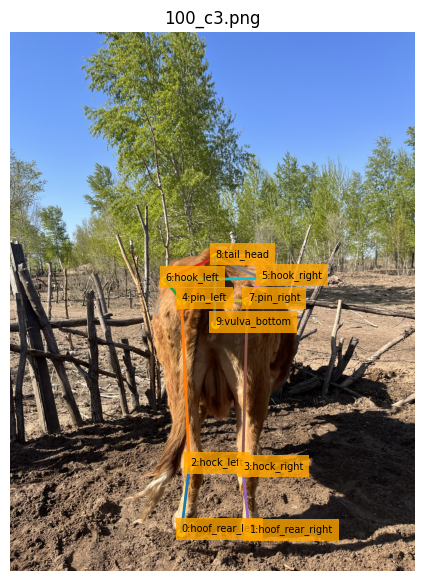

Image: vetra_back_pose_dataset\images\val\20_c2.png


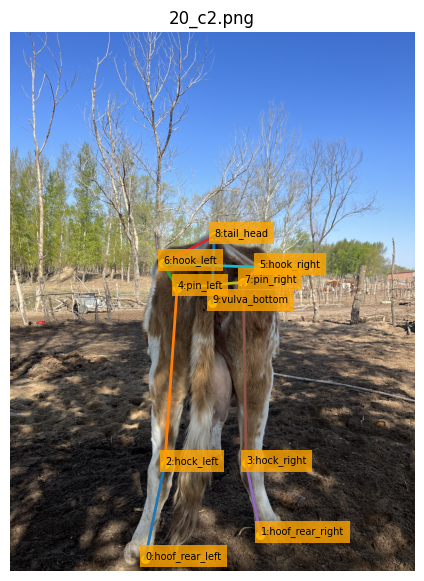

Image: vetra_back_pose_dataset\images\val\111_c3.png


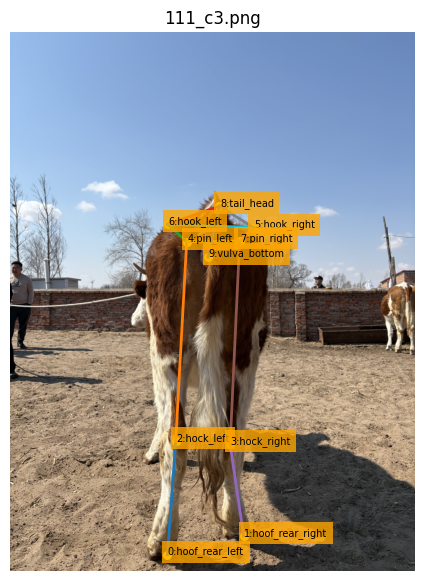

In [11]:
%matplotlib inline
all_back_images = [
    p for p in BACK_IMAGES_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]
print("Found", len(all_back_images), "back-view images in", BACK_IMAGES_DIR)

# Show 3 random examples
for img_path in random.sample(all_back_images, min(3, len(all_back_images))):
    print("Image:", img_path)
    plot_back_pose_on_image(img_path, back_model, conf=0.5)


In [12]:
from pathlib import Path

specific_back_img = Path(r"D:\path\to\one\back_view_image.jpg")
plot_back_pose_on_image(specific_back_img, back_model, conf=0.5)


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\path\\to\\one\\back_view_image.jpg'

In [ ]:
def plot_back_trait_on_image(img_path: Path, model, trait: str, conf: float = 0.5, figsize=(7, 7)):
    edges = BACK_TRAIT_EDGES_IDX.get(trait, [])
    if not edges:
        print(f"No edges defined for trait '{trait}'")
        return

    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No detections.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()

    # Draw only trait edges
    for i, j in edges:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1, x2], [y1, y2], linewidth=3)

    # Draw keypoints involved
    involved = sorted(set([i for e in edges for i in e]))
    for idx in involved:
        x, y = kpts[idx]
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=40)
        plt.text(
            x + 3, y - 3, f"{idx}:{BACK_KEYPOINT_NAMES[idx]}",
            fontsize=8,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
        )

    plt.title(f"{img_path.name} – {trait}")
    plt.show()


Sample: vetra_back_pose_dataset\images\val\99_c0.png


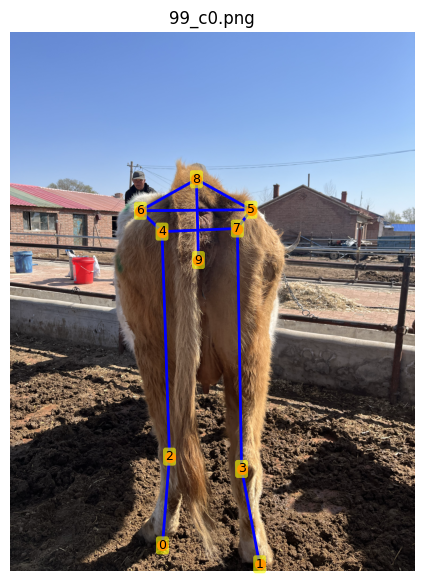

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from pathlib import Path

# --- IMPORTANT ---
# You must ensure the following variables are defined in your notebook 
# before calling this function (they are defined in your prompt):
# - BACK_SKELETON_EDGES
# - BACK_KEYPOINT_NAMES 
# -------------------

def plot_simple_back_skeleton(img_path: Path, model, conf: float = 0.5, figsize=(7, 7)):
    """
    Plots the detected keypoints and skeleton edges on an image, 
    using only the keypoint index (0, 1, 2, ...) for labeling.
    """
    # 1. Read and Convert Image
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print("Could not read image:", img_path)
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 2. Inference
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No keypoints detected.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()  # [num_kpts, 2]

    # 3. Draw Skeleton Edges (Simple Line Connections)
    for i, j in BACK_SKELETON_EDGES:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            # Draw line: simple blue line, thickness 2
            plt.plot([x1, x2], [y1, y2], color='blue', linewidth=2, zorder=1) 

    # 4. Draw Keypoints with Index (Simple Numbers)
    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
            
        # Draw the scatter point: simple red dot, size 50
        plt.scatter(x, y, s=50, color='red', zorder=2) 
        
        # Add the index number (e.g., "0", "1", "2")
        plt.text(
            x, y, str(idx),
            color='black',            # Text color
            fontsize=9,               
            ha='center',              # Center text horizontally on the point
            va='center',              # Center text vertically on the point
            # Optional: Add a subtle background for contrast
            bbox=dict(facecolor='yellow', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.2'),
            zorder=3
        )

    plt.title(img_path.name)
    plt.show()

# --- Example of how to run it ---
# Assuming you have run the setup cells 1-3 from your prompt:

sample = random.choice(all_back_images)
print("Sample:", sample)

# # Use the new simplified function:
plot_simple_back_skeleton(sample, back_model, conf=0.5)

In [ ]:
from pathlib import Path

specific_back_img = Path(r"D:\path\to\one\back_view_image.jpg")

plot_back_pose_on_image(specific_back_img, back_model, conf=0.5)


Scaling

In [13]:
import cv2
import numpy as np
from pathlib import Path

# -------------------------------------------------------------
# ArUco helpers (version-safe for OpenCV 4.x new + legacy API)
# -------------------------------------------------------------

def _get_aruco_dict(dict_name: str = "DICT_4X4_50"):
    """
    Map a string name to an OpenCV ArUco dictionary constant.
    Change dict_name if you use a different marker family.
    """
    name = dict_name.upper()
    ARUCO_DICT = {
        "DICT_4X4_50":   cv2.aruco.DICT_4X4_50,
        "DICT_4X4_100":  cv2.aruco.DICT_4X4_100,
        "DICT_5X5_50":   cv2.aruco.DICT_5X5_50,
        "DICT_5X5_100":  cv2.aruco.DICT_5X5_100,
        "DICT_6X6_50":   cv2.aruco.DICT_6X6_50,
        "DICT_6X6_100":  cv2.aruco.DICT_6X6_100,
        "DICT_7X7_50":   cv2.aruco.DICT_7X7_50,
        "DICT_7X7_100":  cv2.aruco.DICT_7X7_100,
        "DICT_APRILTAG_36h11": cv2.aruco.DICT_APRILTAG_36h11,
    }
    if name not in ARUCO_DICT:
        raise ValueError(f"Unknown ArUco dictionary name: {dict_name}")
    return ARUCO_DICT[name]


def detect_aruco_markers(
    img_bgr,
    dict_name: str = "DICT_4X4_50"
):
    """
    Detect ArUco markers in a BGR image.
    Returns:
        corners: list of (4,1,2) or (4,2) arrays
        ids:     np.array of shape (N,1) or None
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    dict_id = _get_aruco_dict(dict_name)

    # Get dictionary
    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_id)

    # Try new API (OpenCV >= 4.7) first, fallback to legacy
    corners, ids = None, None
    try:
        # New style
        parameters = cv2.aruco.DetectorParameters()
        detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)
        corners, ids, _ = detector.detectMarkers(gray)
    except AttributeError:
        # Old style
        parameters = cv2.aruco.DetectorParameters_create()
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=parameters)

    if ids is None or len(ids) == 0:
        return [], None

    return corners, ids


def draw_aruco_detections(img_bgr, corners, ids):
    """
    Draw detected ArUco markers for visualization.
    """
    out = img_bgr.copy()
    if ids is not None and len(corners) > 0:
        cv2.aruco.drawDetectedMarkers(out, corners, ids)
    return out


def compute_cm_per_pixel_from_aruco(
    corners,
    marker_size_cm: float
):
    """
    Estimate a global cm-per-pixel scale from one or more detected ArUco markers.

    corners: list of marker corners, each shape (4,1,2) or (4,2)
    marker_size_cm: physical side length of the square marker.
    """
    if corners is None or len(corners) == 0:
        raise RuntimeError("No ArUco corners provided to compute scale.")

    all_edge_lengths_px = []

    for m_c in corners:
        c = np.squeeze(m_c)  # -> (4,2)
        if c.shape != (4, 2):
            continue

        # Four edges (0-1, 1-2, 2-3, 3-0)
        edges = [
            np.linalg.norm(c[0] - c[1]),
            np.linalg.norm(c[1] - c[2]),
            np.linalg.norm(c[2] - c[3]),
            np.linalg.norm(c[3] - c[0]),
        ]
        all_edge_lengths_px.extend(edges)

    if not all_edge_lengths_px:
        raise RuntimeError("Could not compute any valid ArUco edge lengths.")

    mean_edge_px = float(np.mean(all_edge_lengths_px))
    cm_per_pixel = marker_size_cm / mean_edge_px

    return {
        "cm_per_pixel": cm_per_pixel,
        "mean_edge_px": mean_edge_px,
        "num_markers": len(corners),
    }


class ScalingEngine:
    """
    Simple scaling engine that currently supports:
      - ArUco based scaling (Tier 1)

    Later we can add:
      - Known reference object
      - Manual two-point reference
    """

    def __init__(self, method: str, cm_per_pixel: float, meta: dict):
        self.method = method
        self.cm_per_pixel = cm_per_pixel
        self.meta = meta

    @classmethod
    def from_aruco(
        cls,
        img_bgr,
        marker_size_cm: float,
        dict_name: str = "DICT_4X4_50"
    ):
        corners, ids = detect_aruco_markers(img_bgr, dict_name=dict_name)
        if ids is None or len(corners) == 0:
            raise RuntimeError("No ArUco markers detected in image for scaling.")

        scale_info = compute_cm_per_pixel_from_aruco(
            corners=corners,
            marker_size_cm=marker_size_cm
        )
        scale_info["dict_name"] = dict_name
        scale_info["marker_size_cm"] = marker_size_cm
        scale_info["marker_ids"] = None if ids is None else ids.flatten().tolist()

        return cls(method="aruco", cm_per_pixel=scale_info["cm_per_pixel"], meta=scale_info), corners, ids


In [14]:
def convert_traits_px_to_cm_with_scale(
    traits_px: dict,
    cm_per_pixel: float
):
    """
    Convert the output of compute_trait_lengths_pixels(...) from pixels to cm
    using a global cm_per_pixel scaling.

    traits_px format (from previous code):
      trait_name -> {
          "total_length_px": float,
          "total_length_px_one_side": float,
          "segment_lengths_px": [...],
          "segments": [(i, j), ...],
          "multiplier": float,
      }
    """
    traits_cm = {}

    for trait, info in traits_px.items():
        total_cm = info["total_length_px"] * cm_per_pixel
        seg_cm = [v * cm_per_pixel for v in info["segment_lengths_px"]]

        traits_cm[trait] = {
            "total_length_cm": float(total_cm),
            "total_length_cm_one_side": float(info["total_length_px_one_side"] * cm_per_pixel),
            "segment_lengths_cm": [float(v) for v in seg_cm],
            "segments": info["segments"],
            "multiplier": info.get("multiplier", 1.0),
            "cm_per_pixel": float(cm_per_pixel),
        }

    return traits_cm


In [15]:
def measure_image_with_aruco_scaling(
    img_path,
    model,
    marker_size_cm: float,
    dict_name: str = "DICT_4X_50",
    conf: float = 0.5,
    show_aruco: bool = True,
):
    """
    End-to-end for one image:
      - detect ArUco markers
      - compute cm/pixel
      - run pose model and get trait pixel measurements
      - convert to cm

    Works for both side-view and back-view pipelines, as long as
    measure_traits_on_image(...) uses the right TRAIT_EDGES_IDX.
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")

    # ---- 1) Build scaling engine from ArUco ----
    scaling_engine, corners, ids = ScalingEngine.from_aruco(
        img_bgr=img_bgr,
        marker_size_cm=marker_size_cm,
        dict_name=dict_name
    )

    print(f"Scaling method   : {scaling_engine.method}")
    print(f"cm_per_pixel     : {scaling_engine.cm_per_pixel:.6f} cm/px")
    print(f"mean_marker_edge : {scaling_engine.meta['mean_edge_px']:.2f} px")
    print(f"num_markers_used : {scaling_engine.meta['num_markers']}")
    print(f"marker_ids       : {scaling_engine.meta['marker_ids']}")

    if show_aruco:
        vis = draw_aruco_detections(img_bgr, corners, ids)
        vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 6))
        plt.imshow(vis_rgb)
        plt.axis("off")
        plt.title(f"Aruco detection: {img_path.name}")
        plt.show()

    # ---- 2) Trait measurement in pixels (your existing function) ----
    meas = measure_traits_on_image(img_path, model=model, conf=conf)
    traits_px = meas["traits_px"]

    if not traits_px:
        print("\nNo trait pixel measurements could be computed.")
        return None, None, scaling_engine

    # ---- 3) Convert to cm using cm_per_pixel from ArUco ----
    traits_cm = convert_traits_px_to_cm_with_scale(
        traits_px=traits_px,
        cm_per_pixel=scaling_engine.cm_per_pixel
    )

    # ---- 4) Print a summary ----
    print("\n=== Trait measurements (pixel + cm from ArUco) ===")
    for trait, info_px in traits_px.items():
        info_cm = traits_cm[trait]
        print(f"\nTrait: {trait}")
        print(f"  total_length_px          : {info_px['total_length_px']:.2f}")
        print(f"  total_length_px_one_side : {info_px['total_length_px_one_side']:.2f}")
        print(f"  total_length_cm          : {info_cm['total_length_cm']:.2f} cm")
        print(f"  total_length_cm_one_side : {info_cm['total_length_cm_one_side']:.2f} cm")
        if info_px.get("multiplier", 1.0) != 1.0:
            print(f"  multiplier               : x{info_px['multiplier']}")
        print(f"  cm_per_pixel             : {info_cm['cm_per_pixel']:.6f} cm/px")

    return traits_px, traits_cm, scaling_engine


In [17]:
# Known physical side length of your ArUco marker (e.g. 10 cm)
MARKER_SIZE_CM = 20.0

img_path_back = r"assets/samples/arc-sample-back.jpg"  # adjust path

traits_px_back, traits_cm_back, scale_back = measure_image_with_aruco_scaling(
    img_path=img_path_back,
    model=back_model,          # your back-view pose model
    marker_size_cm=MARKER_SIZE_CM,
    dict_name="DICT_4X4_50",
    conf=0.5,
    show_aruco=True,
)


RuntimeError: No ArUco markers detected in image for scaling.